In [1]:
import xarray

import plots
import thesis

xarray.set_options(keep_attrs=True)

In [2]:
location = "torino"  # Select the spatial center of the analysis, cf. thesis.coords keys.

dir_data = thesis.dir_data / location / "preprocessed"

In [3]:
ds_reference = xarray.open_dataset(
    dir_data / "reference.nc",
    chunks={"latitude": 1, "longitude": 1, "time": -1}
)

# Evaluate useful climatological quantities.
_groupby = ds_reference.sel(time=thesis.baseline_period).groupby("time.dayofyear")
_quantities = []
_quantities.append(_groupby.mean(dim="time").assign_coords({"quantity": "mean"}))
_quantities.append(_groupby.std(dim="time").assign_coords({"quantity": "std"}))
_quantities.append(_groupby.quantile(0.5, dim="time").drop_vars("quantile").assign_coords({"quantity": "P05"}))
_quantities.append(_groupby.quantile(0.95, dim="time").drop_vars("quantile").assign_coords({"quantity": "P95"}))
ds_climatology = xarray.concat(_quantities, dim="quantity")

# Store climatology in a dedicated file.
ds_climatology.to_netcdf(dir_data / "climatology.nc")

## Anomalies of climate variables

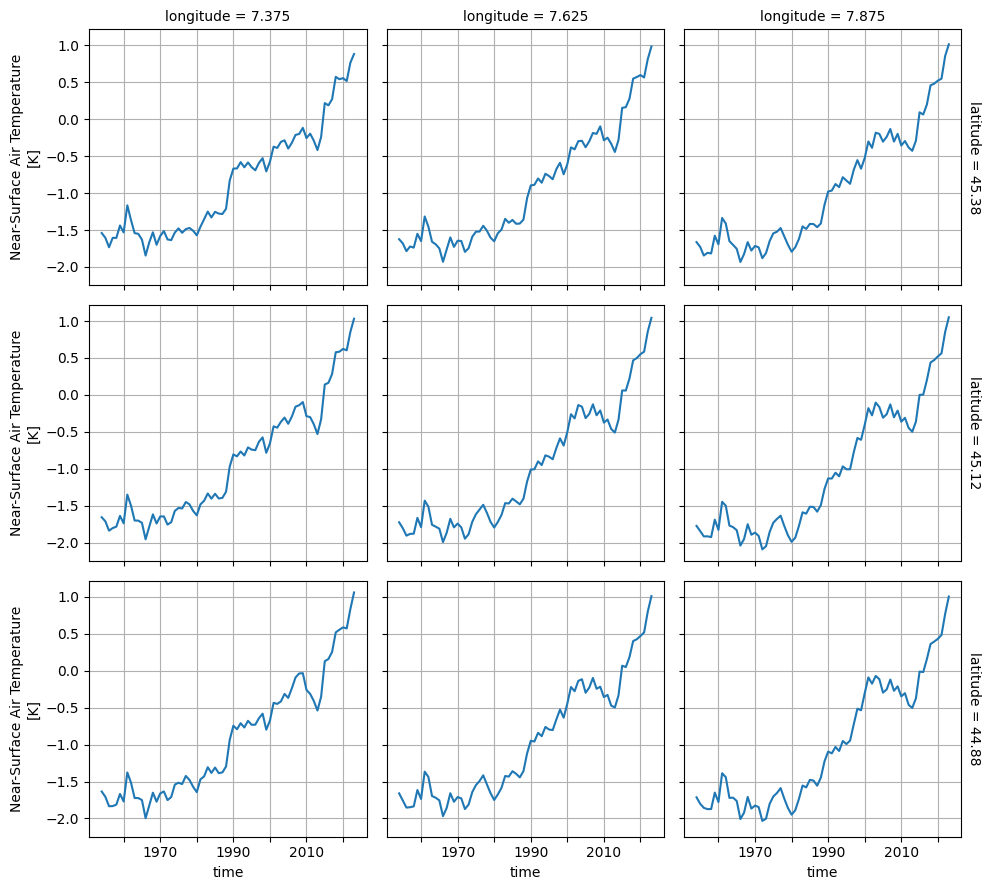

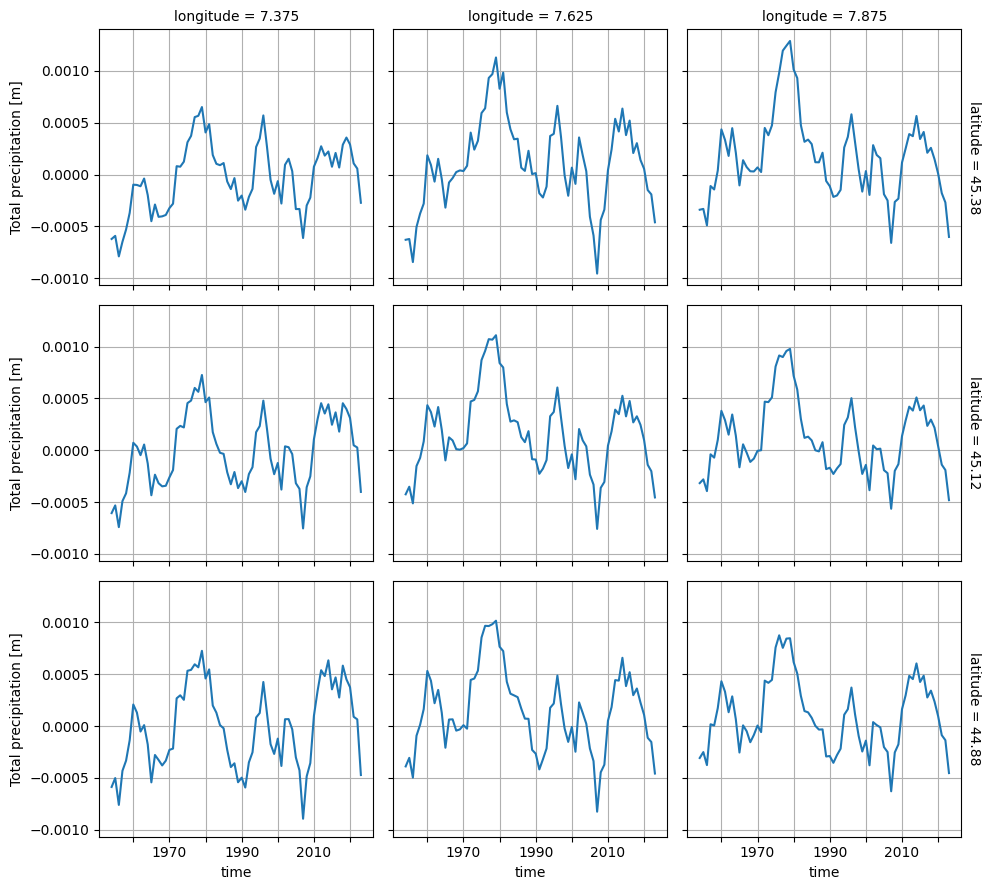

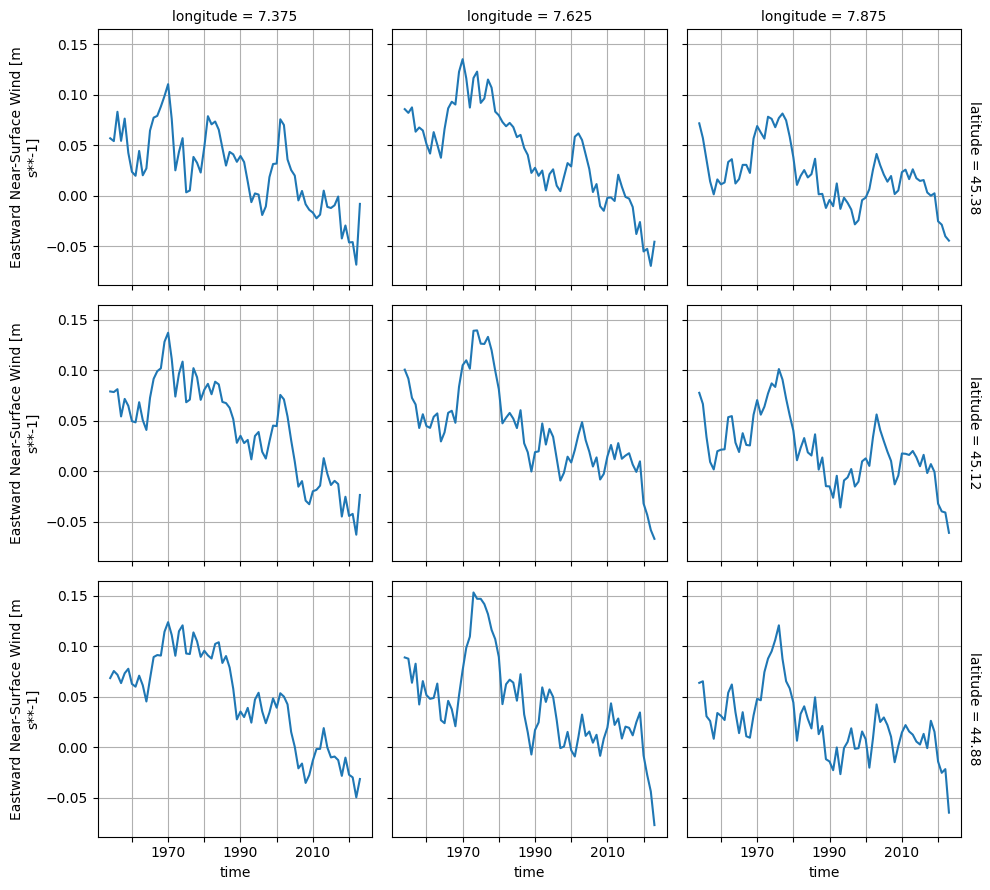

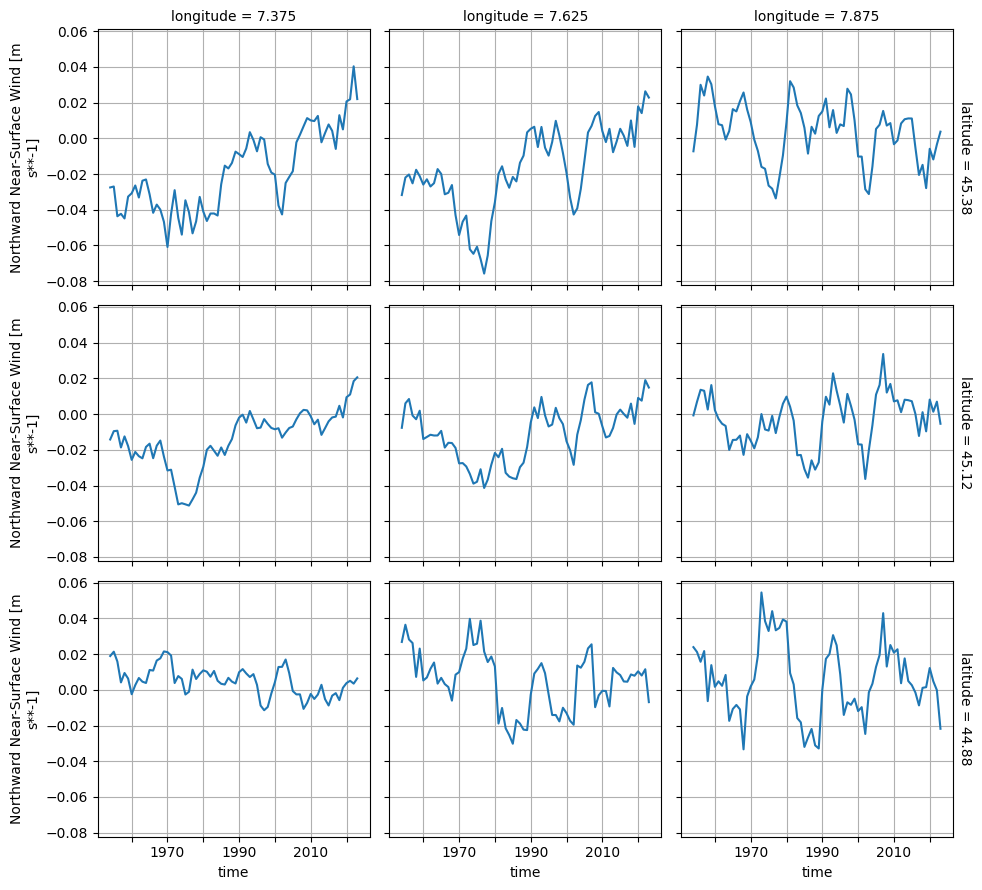

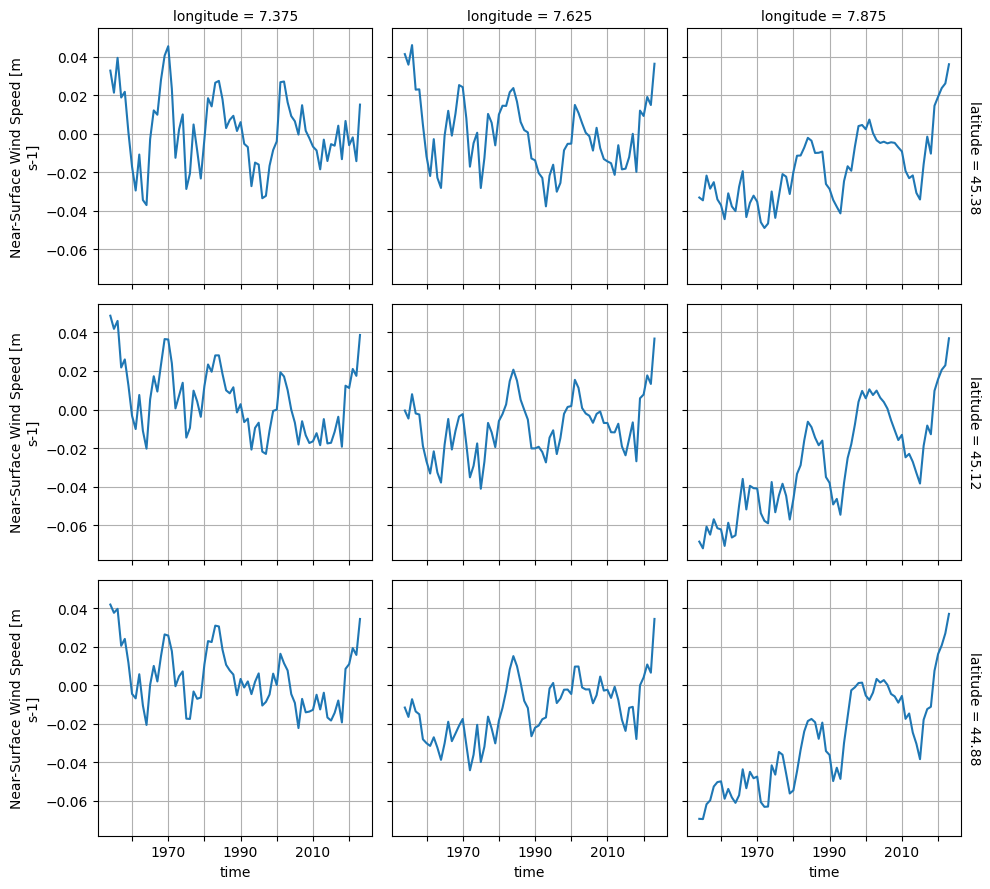

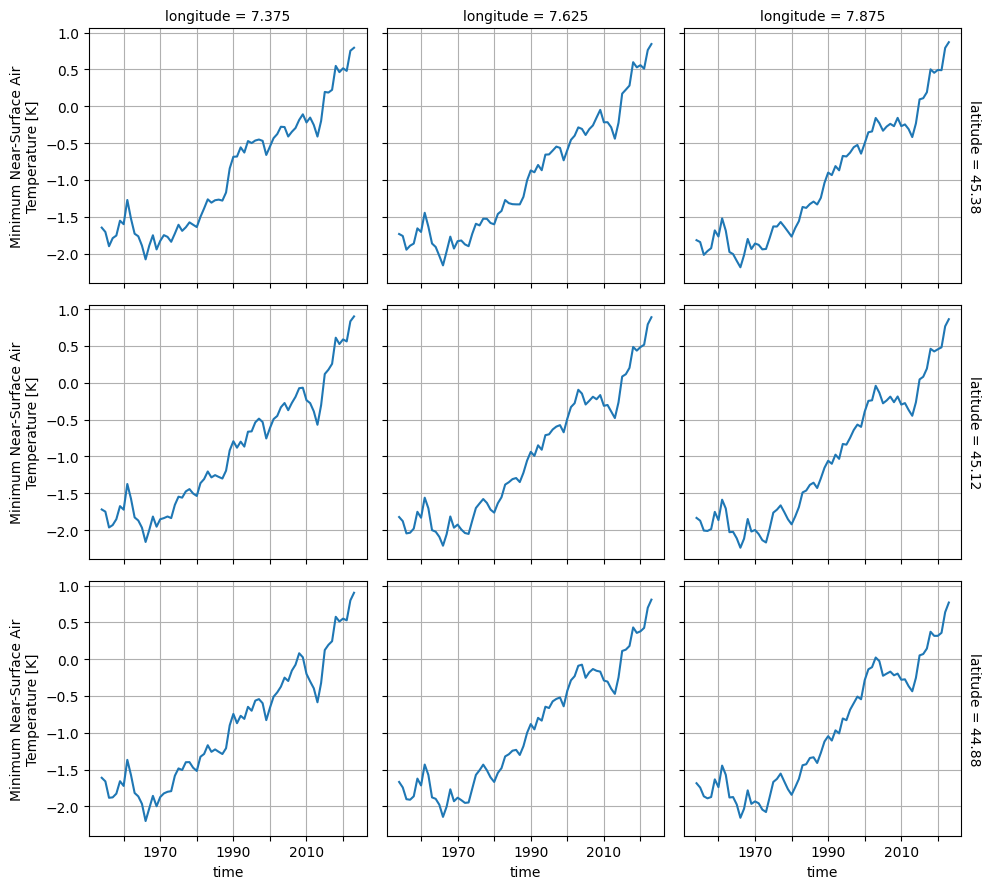

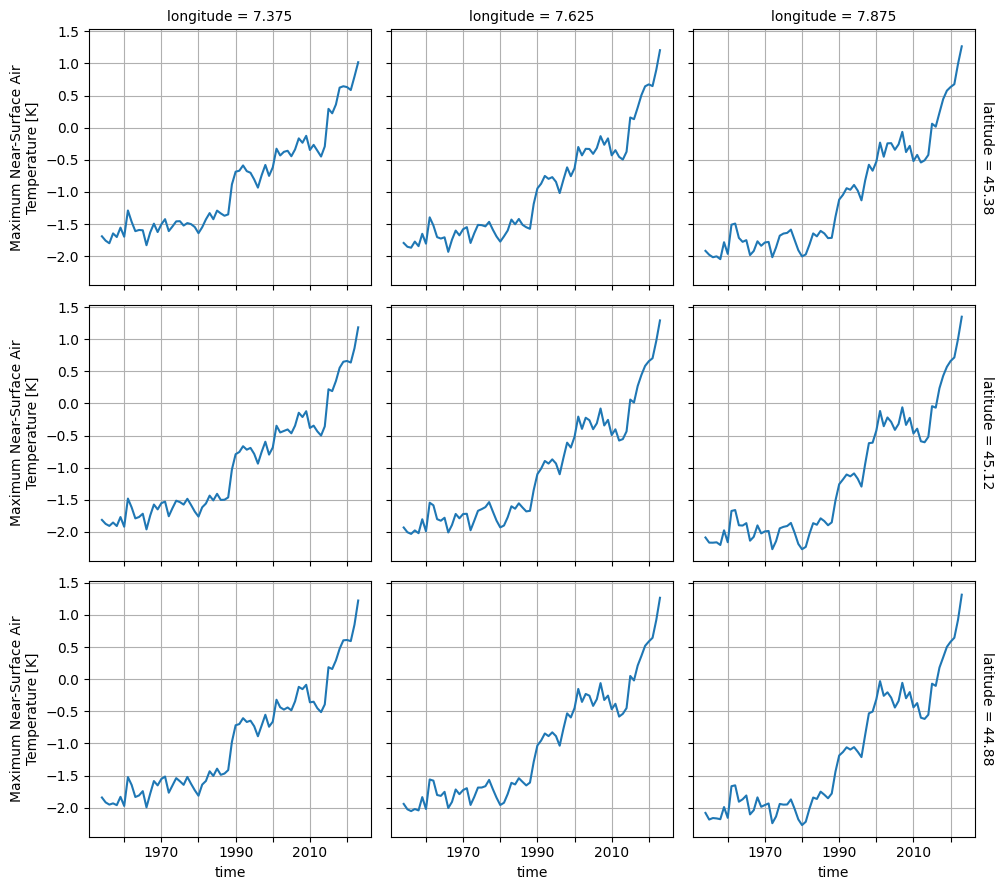

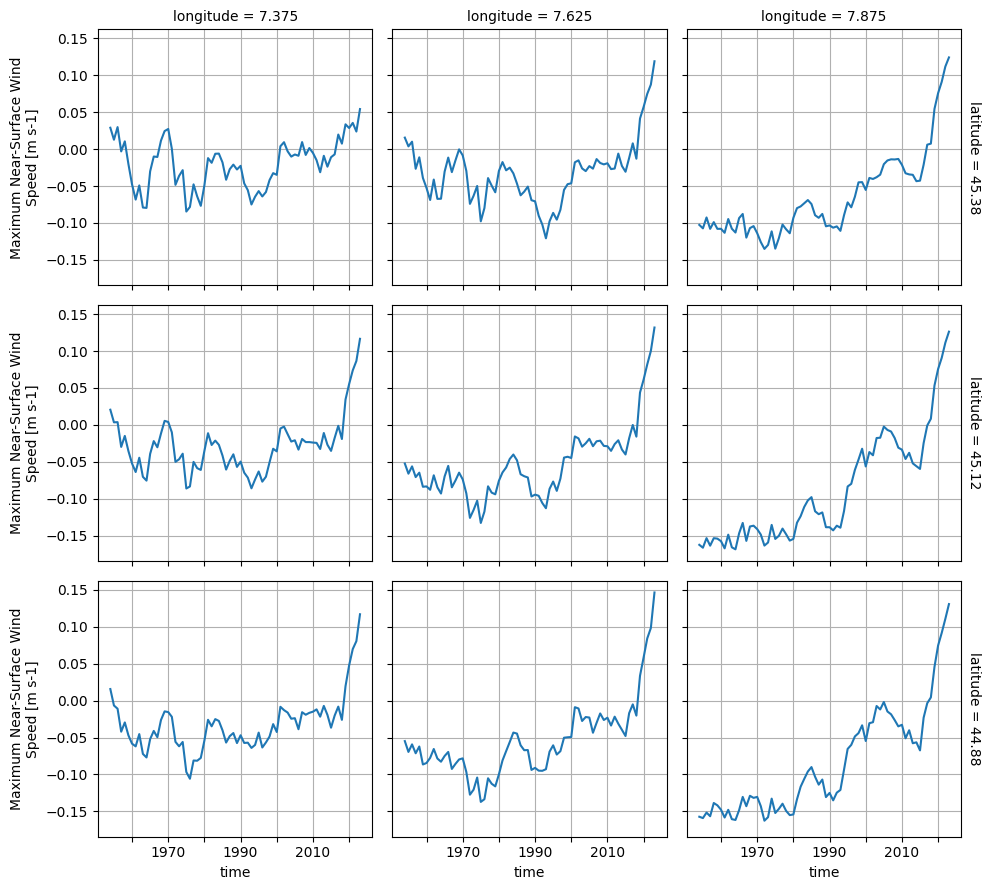

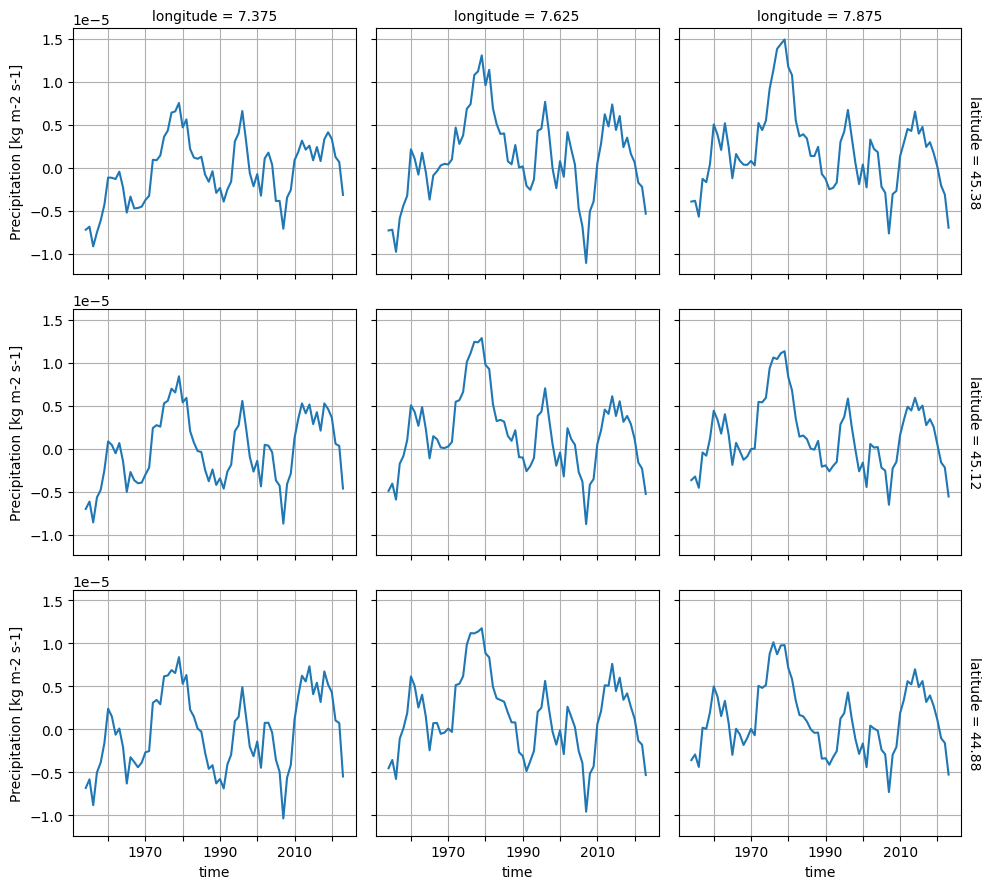

In [4]:
for v in ds_climatology.data_vars:
    plots.daily_anomaly(ds_reference[v], ds_climatology[v])